In [ ]:
# Importing Libraries before work

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (7, 4)

def check(label, test, hint=""):
    """Self-check helper: prints ✅ or ❌ (with a hint)."""
    try:
        ok = bool(test())
    except Exception as e:
        ok, hint = False, f"{hint}  (error: {type(e).__name__}: {e})"
    print(("✅ " if ok else "❌ ") + label + ("" if ok else f"\n   hint: {hint}"))

print("Ready!")

Ready!


In [4]:
# Imported my Data Set
df = pd.read_csv(r"C:\DATA SCIENCE\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [6]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
#Exploring the data set
print("Rows, Column:", df.shape)

Rows, Column: (7043, 21)


In [11]:
# Column names, data types and how many non-empty values each column has
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
# The main issue: TotalCharges is a string (str), not a number. 
# In this dataset it contains blank " " values (about 11 rows, 
# all customers with tenure == 0, i.e. brand new). isna() doesn’t catch them, 
# which is why the non-null count says 7043.

In [ ]:
#To fix this i have converted the Total charge column to nueric 
# and filled the missing values with zero since these customuers havent been billed yet.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())          
print(df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges"]])

# these customers haven't been billed yet, so 0 is the logical fill
df["TotalCharges"] = df["TotalCharges"].fillna(0)

11
      tenure  MonthlyCharges
488        0           52.55
753        0           20.25
936        0           80.85
1082       0           25.75
1340       0           56.05
3331       0           19.85
3826       0           25.35
4380       0           20.00
5218       0           19.70
6670       0           73.35
6754       0           61.90


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [19]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [20]:
# There are no null values in the the data set and now i will check for the duplicate
df.duplicated().sum()

np.int64(0)

In [21]:
# There are no duplicate values in the data set and now i will check for the unique values in the data set
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000,7043.000,7043.000,7043.000
mean,0.162,32.371,64.762,2279.734
std,0.369,24.559,30.090,2266.794
min,0.000,0.000,18.250,0.000
25%,0.000,9.000,35.500,398.550
50%,0.000,29.000,70.350,1394.550
75%,0.000,55.000,89.850,3786.600
max,1.000,72.000,118.750,8684.800


In [ ]:
# There are no outliers in the data set

In [23]:
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].corr())

                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.248         0.826
MonthlyCharges   0.248           1.000         0.651
TotalCharges     0.826           0.651         1.000


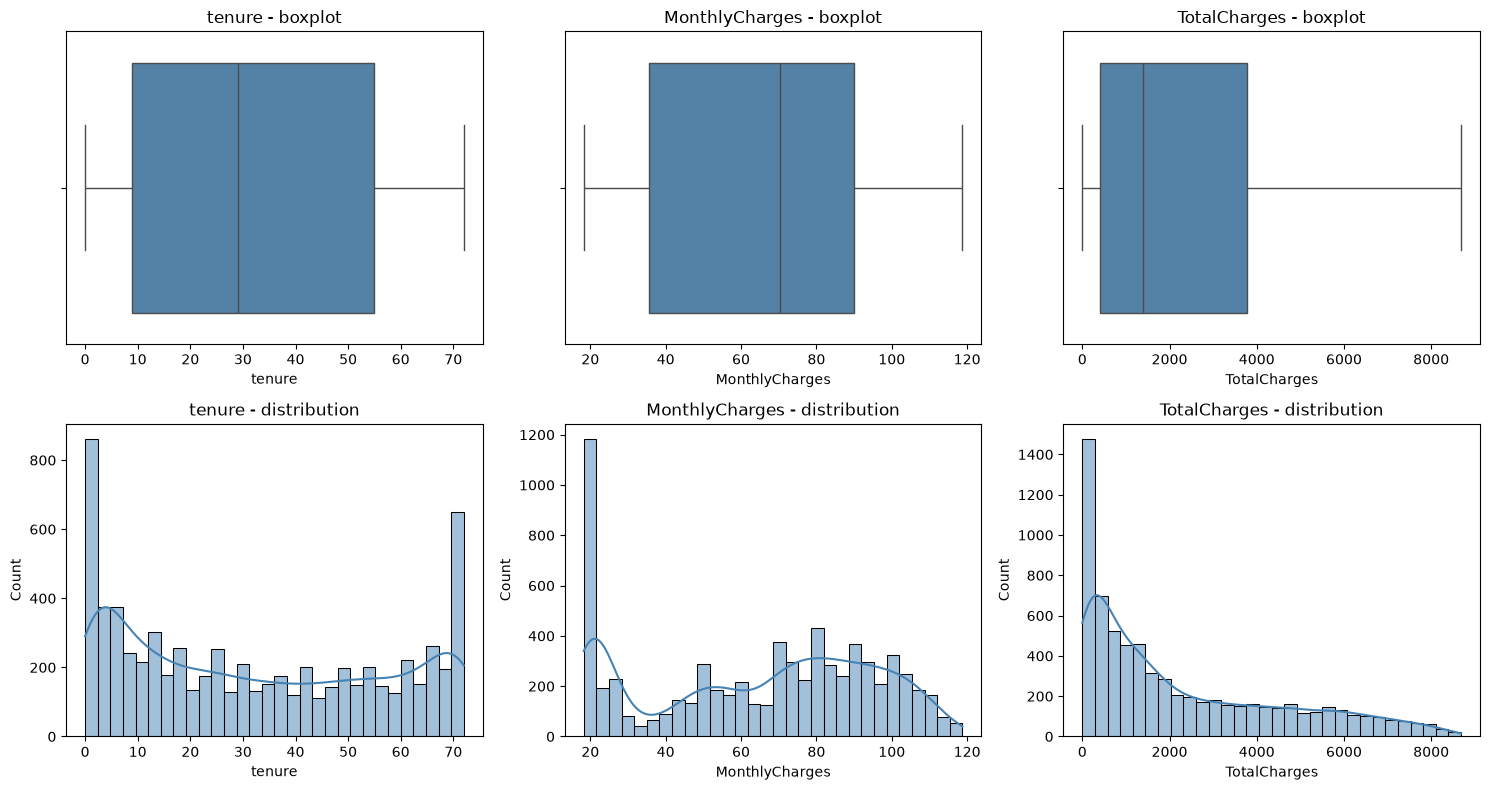

In [24]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(num_cols):
    # Row 1: boxplots
    sns.boxplot(x=df[col], ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"{col} - boxplot")

    # Row 2: histograms
    sns.histplot(df[col], bins=30, kde=True, ax=axes[1, i], color="steelblue")
    axes[1, i].set_title(f"{col} - distribution")

plt.tight_layout()
plt.show()

In [25]:
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {n_out} outliers (fences: {lower:.1f} to {upper:.1f})")

tenure: 0 outliers (fences: -60.0 to 124.0)
MonthlyCharges: 0 outliers (fences: -46.0 to 171.4)
TotalCharges: 0 outliers (fences: -4683.5 to 8868.7)


In [ ]:
# No outliers by the IQR rule; high TotalCharges values reflect long-tenure customers, so all rows were retained.


In [28]:
df.describe()

,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000,7043.000,7043.000,7043.000
mean,32.371,64.762,2279.734,0.265
std,24.559,30.090,2266.794,0.442
min,0.000,18.250,0.000,0.000
25%,9.000,35.500,398.550,0.000
50%,29.000,70.350,1394.550,0.000
75%,55.000,89.850,3786.600,1.000
max,72.000,118.750,8684.800,1.000


In [30]:
df.info()
print(df.isna().sum().sum())    

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [31]:
print(df.duplicated().sum())

22


In [ ]:
# it says there are 22 duplicate rows 
# Why I’d keep them: the original customerID was unique for every row, 
# so these were 22 different customers. Once the ID is removed, 
# some of them look identical because they share the same plan, contract, charges and tenure. 
# That’s a coincidence of matching profiles, not a data-entry error. Removing them would throw away real customers.
 

In [32]:
# To check if the duplicates are a problem
dupes = df[df.duplicated(keep=False)]
print(dupes["Churn"].value_counts())
print(dupes.sort_values(list(df.columns)).head(10))

Churn
1    24
0    18
Name: count, dtype: int64
      gender SeniorCitizen Partner Dependents  tenure PhoneService  \
6491  Female            No      No         No       1          Yes   
6764  Female            No      No         No       1          Yes   
4495  Female            No      No         No       1          Yes   
6267  Female            No      No         No       1          Yes   
5522  Female            No      No         No       1          Yes   
5759  Female            No      No         No       1          Yes   
542   Female            No      No         No       1          Yes   
1491  Female            No      No         No       1          Yes   
5170  Female            No      No         No       1          Yes   
6774  Female            No      No         No       1          Yes   

     MultipleLines InternetService       OnlineSecurity         OnlineBackup  \
6491            No     Fiber optic                   No                   No   
6764            No   

In [ ]:
# Duplicates: 22 rows (0.3%) are identical across all features once customerID is removed. 
# Since customerID was unique for every row, these are distinct customers with matching profiles, not true duplicates, 
# so I kept them. (Removing them would not materially change results.)


In [33]:
# Target is numeric 0/1
print(df["Churn"].value_counts(normalize=True))

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [ ]:
# Categories look clean
cat_cols = df.select_dtypes(include=["object", "string"]).columns
for c in cat_cols:
    print(c, df[c].unique())

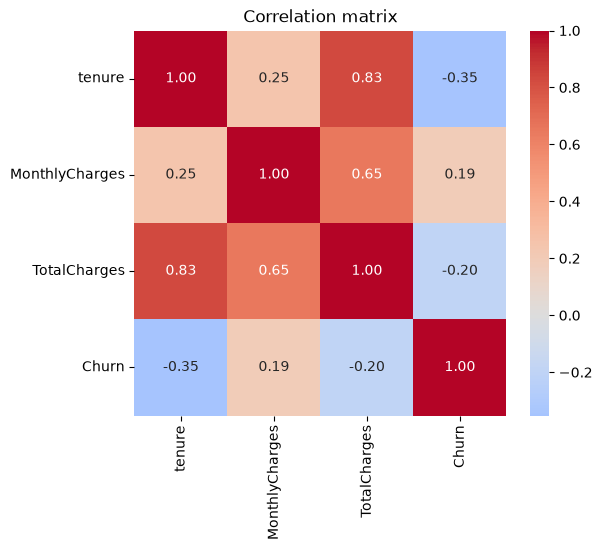

In [ ]:
# Correlation Matrix
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
corr = df[num_cols + ["Churn"]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

In [57]:
# Correlation Matrix with Selected Features
num_cols = ["Contract", "OnlineSecurity", "TechSupport", "InternetService", "PaymentMethod"]
corr = df[num_cols + ["Churn"]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

ValueError: could not convert string to float: 'Month-to-month'

In [34]:
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,0
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,0
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,1


In [39]:

X = df.drop(columns=["Churn"])
X

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45
7041,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60


In [38]:
y = df["Churn"]
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [41]:
# Checking how many customer churned 
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [42]:
# Percentage of customers who churned
df["Churn"].value_counts(normalize=True) * 100

Churn
0    73.463
1    26.537
Name: proportion, dtype: float64

In [43]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [44]:
# Contract Category
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [45]:
# Summarising numerical and categorical columns.
df.describe(include="all")

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043,7043,7043.000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000,7043.000,7043.000
unique,2,2,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,NaN
top,Male,No,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,NaN
freq,3555,5901,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,32.371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.762,2279.734,0.265
std,NaN,NaN,NaN,NaN,24.559,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090,2266.794,0.442
min,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250,0.000,0.000
25%,NaN,NaN,NaN,NaN,9.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500,398.550,0.000
50%,NaN,NaN,NaN,NaN,29.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350,1394.550,0.000
75%,NaN,NaN,NaN,NaN,55.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850,3786.600,1.000


In [46]:
# Calculating Churn rate by Contract type
df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64

In [47]:
# For numerical features, compare the distributions of customers who stayed and customers who left.
df.groupby("Churn")["tenure"].mean()

Churn
0    37.570
1    17.979
Name: tenure, dtype: float64

In [48]:
# Comparing Churn by monthly charges
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
0    61.265
1    74.441
Name: MonthlyCharges, dtype: float64

In [49]:
# 2. Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

In [50]:
# Identify all categorical columns, excluding the target

categorical_columns = df.select_dtypes(
    include=["object", "str", "category"]
).columns.drop("Churn", errors="ignore")

# Create an empty list to store the results
results = []

# Loop through every categorical feature
for column in categorical_columns:

    # Calculate churn rate for each category
    churn_rate = df.groupby(column)["Churn"].mean() * 100

    # Calculate customer count for each category
    customer_count = df.groupby(column)["Churn"].count()

    # Store the results
    for category in churn_rate.index:
        results.append({
            "Feature": column,
            "Category": category,
            "Customers": customer_count.loc[category],
            "Churn_Rate_%": churn_rate.loc[category]
        })

# Convert results into a DataFrame
churn_analysis = pd.DataFrame(results)

# Sort by churn rate, highest first
churn_analysis = churn_analysis.sort_values(
    by="Churn_Rate_%",
    ascending=False
)

# Display the results
churn_analysis

,Feature,Category,Customers,Churn_Rate_%
41,PaymentMethod,Electronic check,2365,45.285
34,Contract,Month-to-month,3875,42.710
14,InternetService,Fiber optic,3096,41.893
16,OnlineSecurity,No,3498,41.767
3,SeniorCitizen,Yes,1142,41.681
25,TechSupport,No,3473,41.635
19,OnlineBackup,No,3088,39.929
22,DeviceProtection,No,3095,39.128
31,StreamingMovies,No,2785,33.680
38,PaperlessBilling,Yes,4171,33.565


In [51]:
# Calculate the highest and lowest churn rates for each feature
feature_ranking = (
    churn_analysis
    .groupby("Feature")
    .agg(
        Highest_Churn_Rate=("Churn_Rate_%", "max"),
        Lowest_Churn_Rate=("Churn_Rate_%", "min"),
        Total_Customers=("Customers", "sum"),
        Number_of_Categories=("Category", "nunique")
    )
)

# Calculate the difference between the highest and lowest rates
feature_ranking["Churn_Rate_Range"] = (
    feature_ranking["Highest_Churn_Rate"]
    - feature_ranking["Lowest_Churn_Rate"]
)

# Rank the features by churn-rate range
feature_ranking = feature_ranking.sort_values(
    by="Churn_Rate_Range",
    ascending=False
)

feature_ranking

,Highest_Churn_Rate,Lowest_Churn_Rate,Total_Customers,Number_of_Categories,Churn_Rate_Range
Feature,,,,,
Contract,42.710,2.832,7043,3,39.878
InternetService,41.893,7.405,7043,3,34.488
OnlineSecurity,41.767,7.405,7043,3,34.362
TechSupport,41.635,7.405,7043,3,34.230
OnlineBackup,39.929,7.405,7043,3,32.524
DeviceProtection,39.128,7.405,7043,3,31.723
PaymentMethod,45.285,15.243,7043,4,30.042
StreamingMovies,33.680,7.405,7043,3,26.275
StreamingTV,33.523,7.405,7043,3,26.118


In [52]:
# Separate the target from the input features
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Convert categorical columns into binary columns
X_encoded = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "str", "category"]).columns,
    drop_first=False,
    dtype=int
)

# Add the target back for analysis
df_encoded = X_encoded.copy()
df_encoded["Churn"] = y

# Display the first five rows
df_encoded.head()

,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,SeniorCitizen_No,SeniorCitizen_Yes,Partner_No,Partner_Yes,Dependents_No,...,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn
0,1,29.85,29.85,1,0,1,0,0,1,1,...,1,0,0,0,1,0,0,1,0,0
1,34,56.95,1889.50,0,1,1,0,1,0,1,...,0,1,0,1,0,0,0,0,1,0
2,2,53.85,108.15,0,1,1,0,1,0,1,...,1,0,0,0,1,0,0,0,1,1
3,45,42.30,1840.75,0,1,1,0,1,0,1,...,0,1,0,1,0,1,0,0,0,0
4,2,70.70,151.65,1,0,1,0,1,0,1,...,1,0,0,0,1,0,0,1,0,1


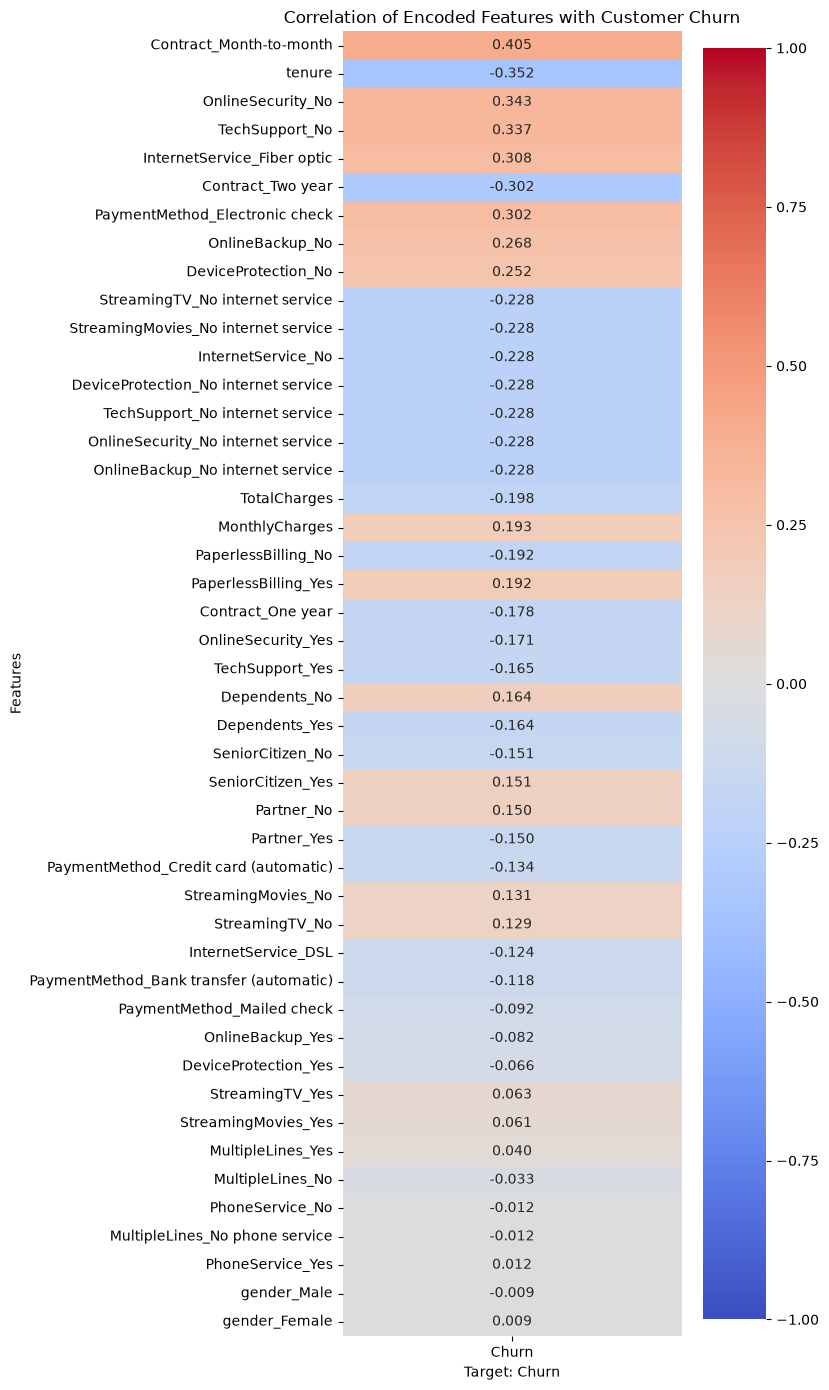

In [53]:
# Calculate the correlation of every feature with Churn
churn_correlations = (
    df_encoded.corr(numeric_only=True)["Churn"]
    .drop("Churn")
    .sort_values(key=abs, ascending=False)
)

# Convert the correlations into a DataFrame for plotting
heatmap_data = churn_correlations.to_frame()

# Plot the heatmap
plt.figure(figsize=(8, 14))

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation of Encoded Features with Customer Churn")
plt.xlabel("Target: Churn")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

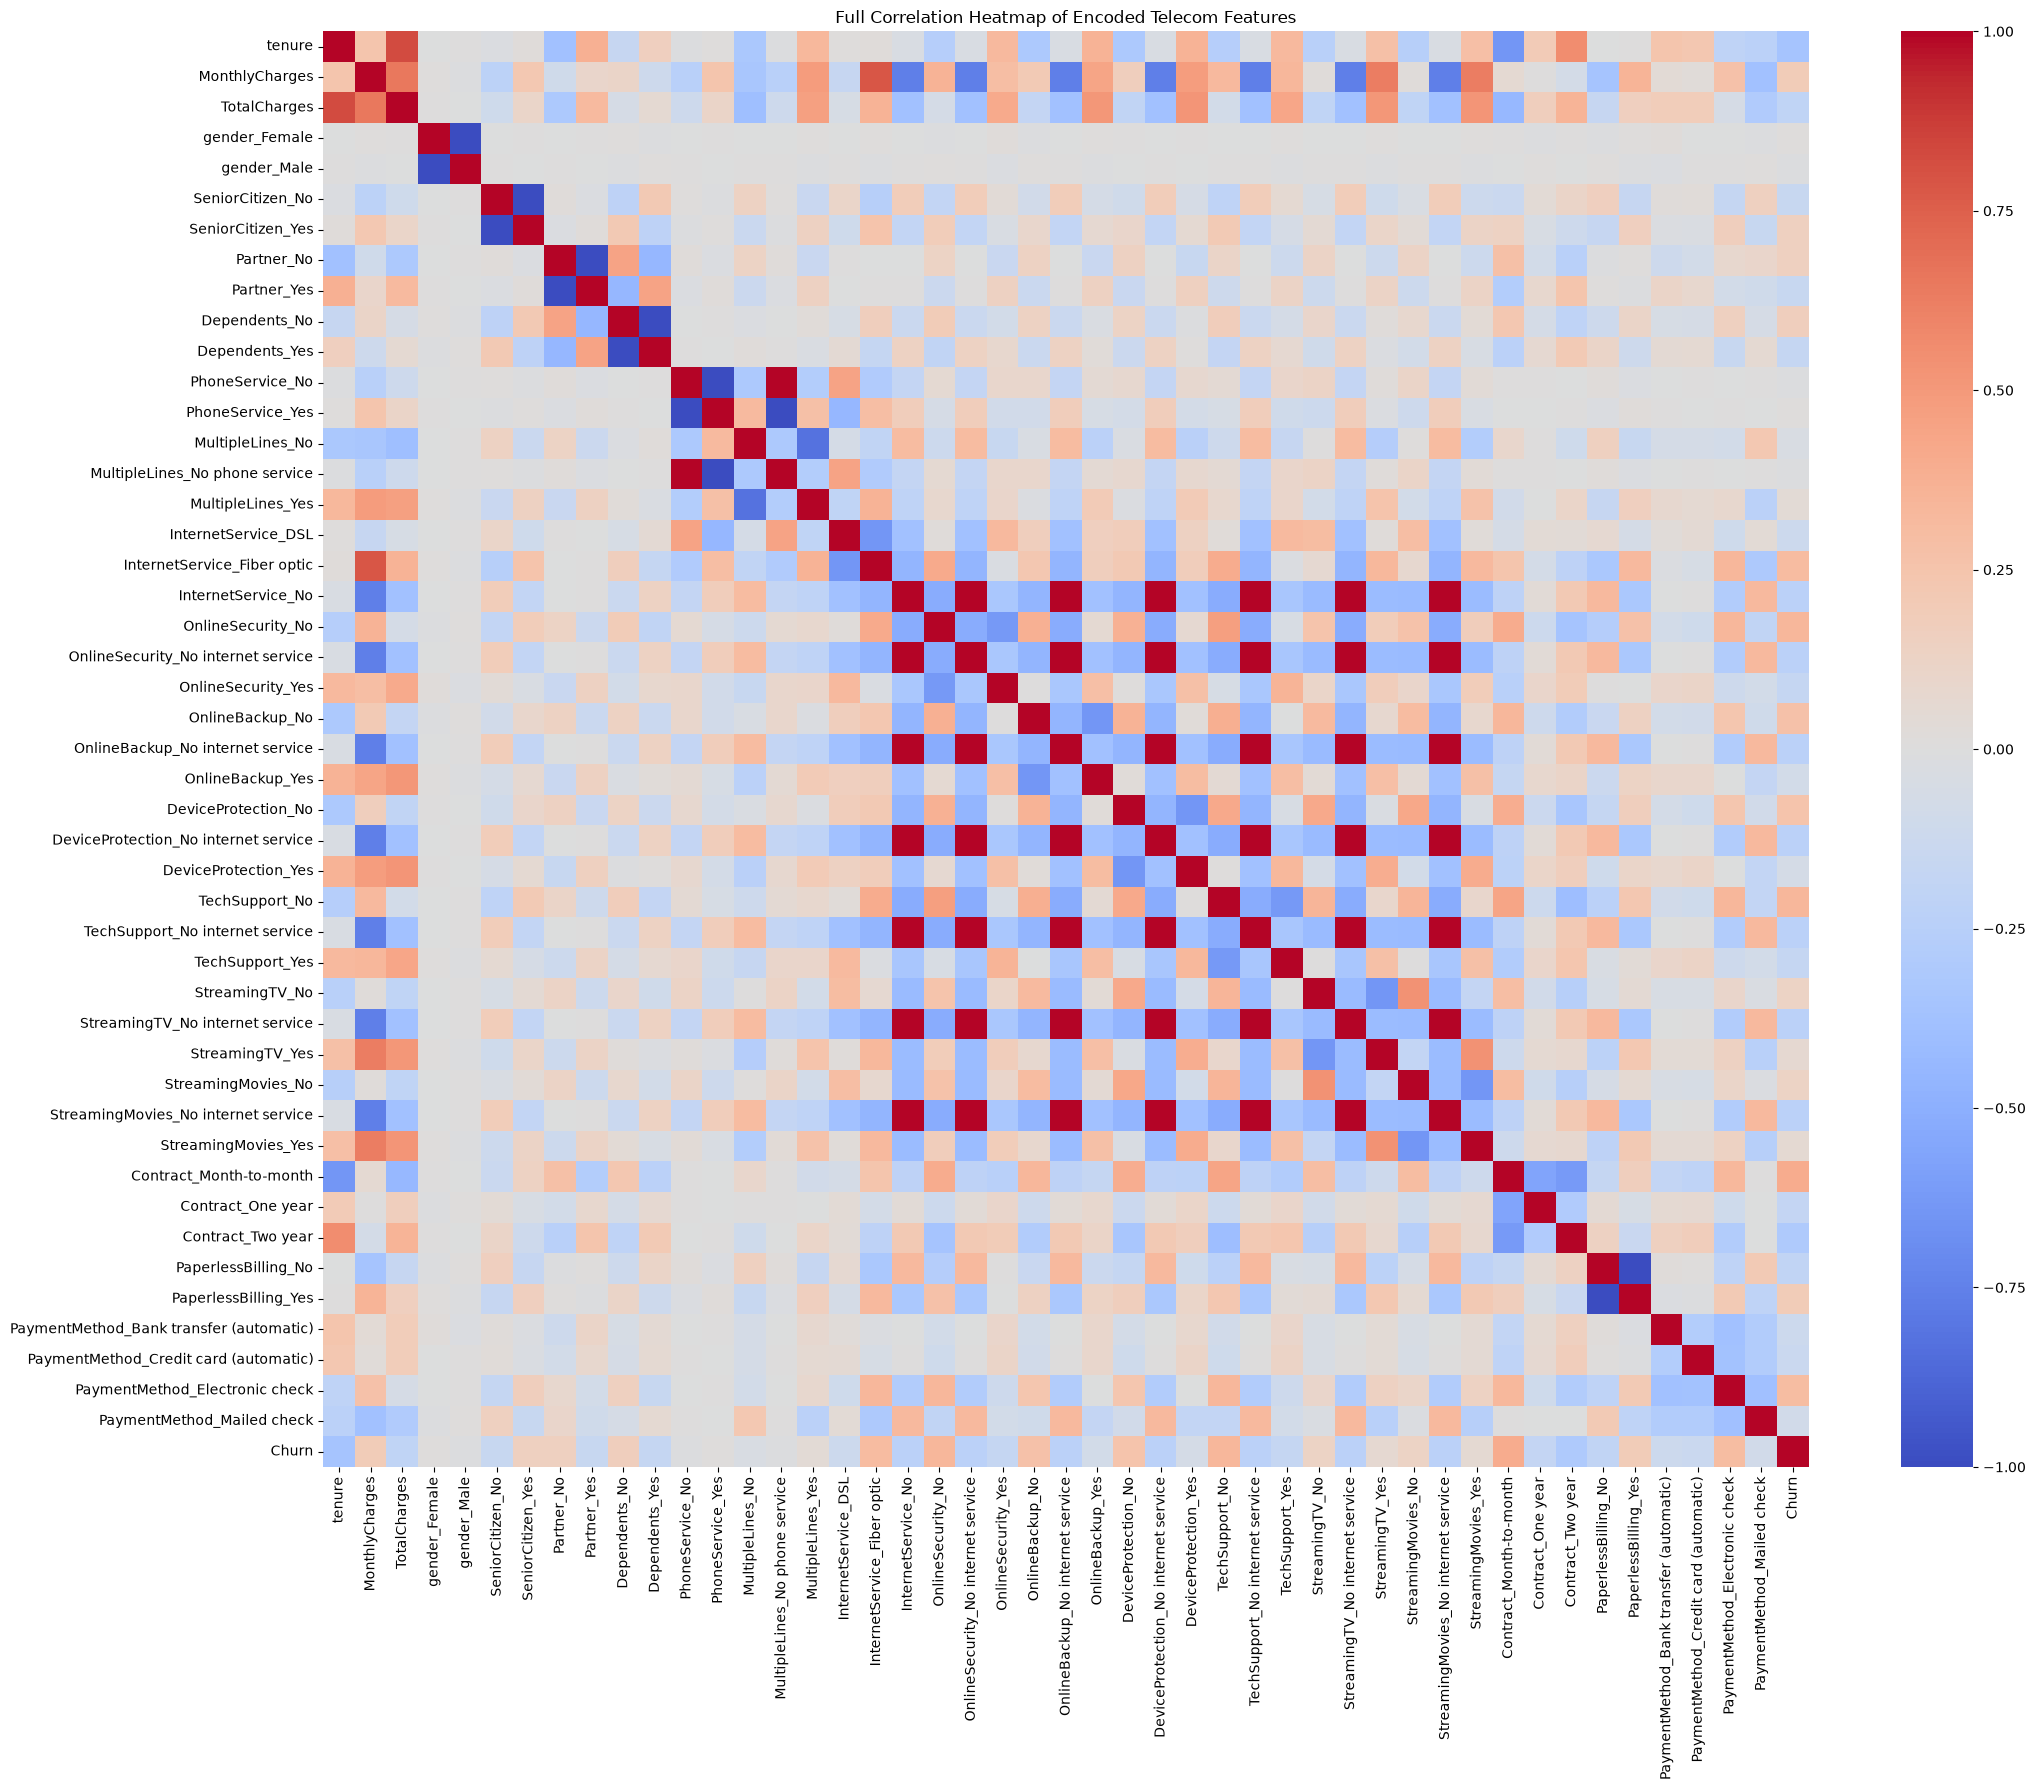

In [54]:
plt.figure(figsize=(22, 18))

correlation_matrix = df_encoded.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Full Correlation Heatmap of Encoded Telecom Features")
plt.tight_layout()
plt.show()

In [55]:
from scipy.stats import chi2_contingency

# Select the categorical features
categorical_features = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Calculate Cramér's V for each feature against Churn
cramers_results = []

for feature in categorical_features:

    contingency_table = pd.crosstab(
        df[feature],
        df["Churn"]
    )

    chi2 = chi2_contingency(
        contingency_table
    )[0]

    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    cramers_results.append({
        "Feature": feature,
        "Cramers_V": cramers_v
    })

# Create and rank the results
cramers_ranking = pd.DataFrame(
    cramers_results
).sort_values(
    by="Cramers_V",
    ascending=False
)

cramers_ranking

,Feature,Cramers_V
13,Contract,0.410
7,OnlineSecurity,0.347
10,TechSupport,0.343
6,InternetService,0.322
15,PaymentMethod,0.303
8,OnlineBackup,0.292
9,DeviceProtection,0.282
12,StreamingMovies,0.231
11,StreamingTV,0.231
14,PaperlessBilling,0.191


In [56]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numerical_features + ["Churn"]].corr()["Churn"].sort_values()

tenure           -0.352
TotalCharges     -0.198
MonthlyCharges    0.193
Churn             1.000
Name: Churn, dtype: float64

In [58]:
# Select the features (X)
X = df[
    [
        "Contract",
        "OnlineSecurity",
        "TechSupport",
        "InternetService",
        "PaymentMethod"
    ]
]

# Select the target (y)
y = df["Churn"]

# Display the first five rows of the features
X.head()

,Contract,OnlineSecurity,TechSupport,InternetService,PaymentMethod
0,Month-to-month,No,No,DSL,Electronic check
1,One year,Yes,No,DSL,Mailed check
2,Month-to-month,Yes,No,DSL,Mailed check
3,One year,Yes,Yes,DSL,Bank transfer (automatic)
4,Month-to-month,No,No,Fiber optic,Electronic check


In [59]:
# Check data types
print(X.dtypes)

# Check for missing values
print(X.isnull().sum())

# Check the distribution of the target
print(y.value_counts())

# Check the percentage distribution of the target
print(y.value_counts(normalize=True) * 100)

Contract           str
OnlineSecurity     str
TechSupport        str
InternetService    str
PaymentMethod      str
dtype: object
Contract           0
OnlineSecurity     0
TechSupport        0
InternetService    0
PaymentMethod      0
dtype: int64
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    73.463
1    26.537
Name: proportion, dtype: float64


In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 5)
Testing features: (1409, 5)
Training target: (5634,)
Testing target: (1409,)


In [64]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [65]:
# One-Hot Encode your categorical features

# List the categorical features
categorical_features = [
    "Contract",
    "OnlineSecurity",
    "TechSupport",
    "InternetService",
    "PaymentMethod"
]

# Create the encoder
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop"
)

# Fit the encoder on training data and transform it
X_train_encoded = preprocessor.fit_transform(X_train)

# Transform the testing data using the same encoder
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (5634, 16)
Encoded testing shape: (1409, 16)


In [66]:
encoded_feature_names = preprocessor.get_feature_names_out()

print(encoded_feature_names)

['categorical__Contract_Month-to-month' 'categorical__Contract_One year'
 'categorical__Contract_Two year' 'categorical__OnlineSecurity_No'
 'categorical__OnlineSecurity_No internet service'
 'categorical__OnlineSecurity_Yes' 'categorical__TechSupport_No'
 'categorical__TechSupport_No internet service'
 'categorical__TechSupport_Yes' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No'
 'categorical__PaymentMethod_Bank transfer (automatic)'
 'categorical__PaymentMethod_Credit card (automatic)'
 'categorical__PaymentMethod_Electronic check'
 'categorical__PaymentMethod_Mailed check']


In [ ]:
# Build your first Logistic Regression model
# Now that your data is encoded, you can train a model to predict churn.
# We'll use Logistic Regression as your baseline model because it is a common starting point for binary classification.

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_encoded, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [68]:
# Make predictions
# Now ask the model to predict churn for the test data.
# Predict the class: 0 or 1
y_pred = model.predict(X_test_encoded)

# Predict the probability of churn
y_pred_proba = model.predict_proba(X_test_encoded)[:, 1]

print("First 10 predictions:", y_pred[:10])

print("First 10 churn probabilities:", y_pred_proba[:10])

First 10 predictions: [0 0 0 1 0 0 0 0 0 0]
First 10 churn probabilities: [0.03262149 0.38315484 0.05750575 0.54309104 0.0228448  0.48711292
 0.38984236 0.12027776 0.01375666 0.45177271]


In [69]:
# Evaluate your model using different metrics
# This is one of the most important stages of your project.
# We'll evaluate the model using:

# Accuracy, Precision, Recall,F1-score, ROC-AUC, Confusion matrix, Classification report
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_pred_proba
)

# Display the results
print("MODEL EVALUATION")
print("----------------------------")
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"ROC-AUC:   {roc_auc:.3f}")

MODEL EVALUATION
----------------------------
Accuracy:  0.764
Precision: 0.584
Recall:    0.390
F1-score:  0.468
ROC-AUC:   0.813


# Display the confusion matrix
# The confusion matrix shows how many predictions were correct and incorrect.

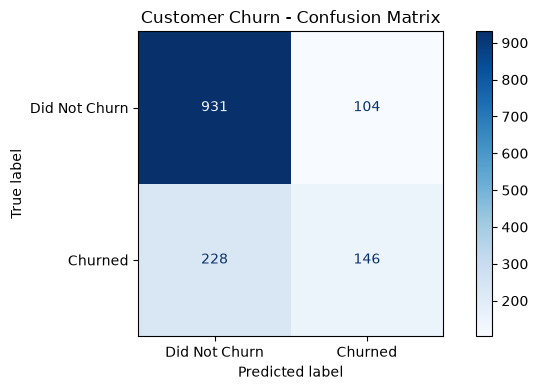

In [70]:
# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Churn", "Churned"]
)

disp.plot(cmap="Blues")

plt.title("Customer Churn - Confusion Matrix")
plt.tight_layout()
plt.show()

In [71]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Did Not Churn", "Churned"],
        zero_division=0
    )
)

               precision    recall  f1-score   support

Did Not Churn       0.80      0.90      0.85      1035
      Churned       0.58      0.39      0.47       374

     accuracy                           0.76      1409
    macro avg       0.69      0.64      0.66      1409
 weighted avg       0.75      0.76      0.75      1409



In [ ]:
# Put your results into a comparison table
# For your portfolio, it is useful to display your model metrics in a DataFrame.


In [72]:
model_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

model_results["Score"] = model_results["Score"].round(3)

model_results

,Metric,Score
0,Accuracy,0.764
1,Precision,0.584
2,Recall,0.390
3,F1-score,0.468
4,ROC-AUC,0.813


In [73]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [74]:
# Define the algorithms
# We'll create a dictionary containing the four algorithms.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42
    ),

    "K-Nearest Neighbours": KNeighborsClassifier(
        n_neighbors=5
    )
}

In [75]:
# Train the models and calculate the metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Prepare models, using scaling for KNN
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42
    ),

    "K-Nearest Neighbours": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

results = []

# Train and evaluate each model
for algorithm, model in models.items():

    # Train the algorithm
    model.fit(X_train_encoded, y_train)

    # Evaluate both training and testing datasets
    for dataset_name, X_data, y_data in [
        ("Train", X_train_encoded, y_train),
        ("Test", X_test_encoded, y_test)
    ]:

        # Predict classes
        y_pred = model.predict(X_data)

        # Predict probabilities for the positive class
        y_proba = model.predict_proba(X_data)[:, 1]

        # Calculate the metrics
        results.append({
            "Algorithm": algorithm,
            "Dataset": dataset_name,
            "Accuracy": accuracy_score(y_data, y_pred),
            "Precision": precision_score(
                y_data, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_data, y_pred, zero_division=0
            ),
            "F1-score": f1_score(
                y_data, y_pred, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_data, y_proba)
        })

# Create the comparison table
performance_table = pd.DataFrame(results)

# Round the metrics to three decimal places
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

performance_table[metric_columns] = (
    performance_table[metric_columns].round(3)
)

performance_table

,Algorithm,Dataset,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,Train,0.784,0.636,0.432,0.515,0.826
1,Logistic Regression,Test,0.764,0.584,0.390,0.468,0.813
2,Decision Tree,Train,0.785,0.652,0.403,0.498,0.828
3,Decision Tree,Test,0.769,0.605,0.369,0.458,0.810
4,Random Forest,Train,0.785,0.629,0.459,0.531,0.834
5,Random Forest,Test,0.774,0.601,0.439,0.507,0.808
6,K-Nearest Neighbours,Train,0.777,0.606,0.456,0.520,0.763
7,K-Nearest Neighbours,Test,0.753,0.547,0.404,0.465,0.738


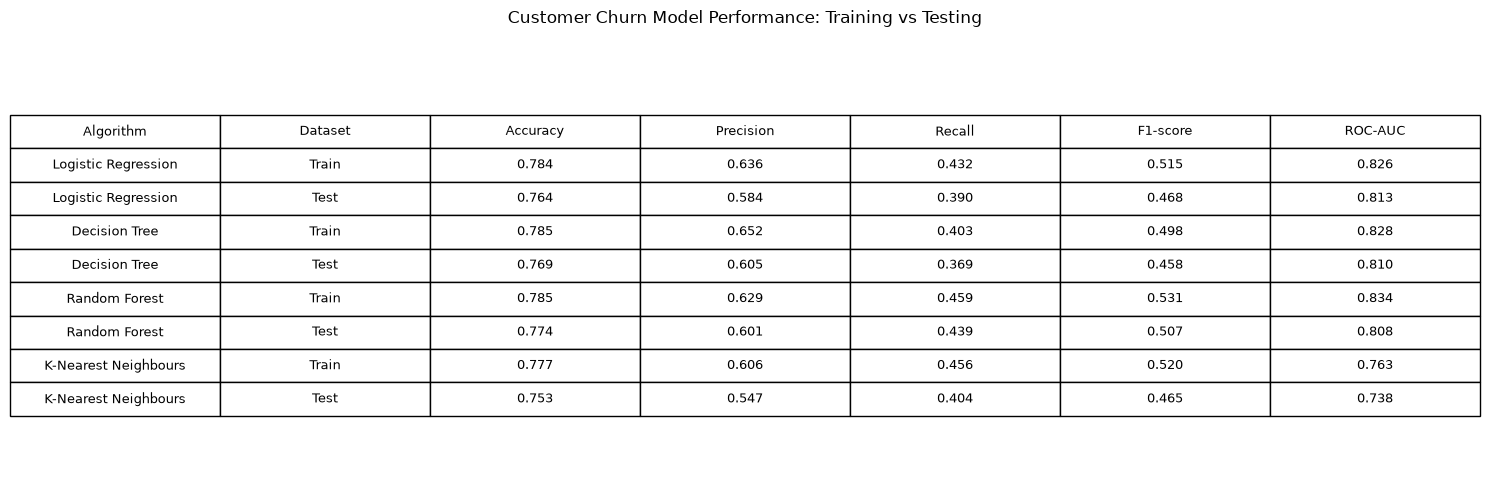

In [76]:
# Plot the performance table

# Create a copy for plotting

plot_data = performance_table.copy()

# Convert metric values to display-friendly strings
for column in metric_columns:
    plot_data[column] = plot_data[column].map(
        lambda value: f"{value:.3f}"
    )

# Create the figure
fig, ax = plt.subplots(figsize=(15, 5))

ax.axis("off")

table = ax.table(
    cellText=plot_data.values,
    colLabels=plot_data.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

plt.title(
    "Customer Churn Model Performance: Training vs Testing",
    pad=20
)

plt.tight_layout()
plt.show()

In [77]:
# Let's calculate these differences for all four algorithms
# Create a table containing training and testing accuracy
accuracy_comparison = performance_table.pivot(
    index="Algorithm",
    columns="Dataset",
    values="Accuracy"
)

# Calculate the accuracy gap
accuracy_comparison["Accuracy_Gap"] = (
    accuracy_comparison["Train"]
    - accuracy_comparison["Test"]
)

accuracy_comparison = accuracy_comparison.round(3)

accuracy_comparison

Dataset,Test,Train,Accuracy_Gap
Algorithm,,,
Decision Tree,0.769,0.785,0.016
K-Nearest Neighbours,0.753,0.777,0.024
Logistic Regression,0.764,0.784,0.020
Random Forest,0.774,0.785,0.011


In [78]:
# Calculate the generalisation gap for every metric
# Reshape the results so Train and Test appear side by side
generalisation_table = performance_table.pivot(
    index="Algorithm",
    columns="Dataset",
    values=metric_columns
)

# Calculate the gap for each metric
for metric in metric_columns:
    generalisation_table[(metric, "Gap")] = (
        generalisation_table[(metric, "Train")]
        - generalisation_table[(metric, "Test")]
    )

generalisation_table = generalisation_table.round(3)

generalisation_table

Accuracy        Precision        Recall        F1-score  \
Dataset                  Test  Train      Test  Train   Test  Train     Test   
Algorithm                                                                      
Decision Tree           0.769  0.785     0.605  0.652  0.369  0.403    0.458   
K-Nearest Neighbours    0.753  0.777     0.547  0.606  0.404  0.456    0.465   
Logistic Regression     0.764  0.784     0.584  0.636  0.390  0.432    0.468   
Random Forest           0.774  0.785     0.601  0.629  0.439  0.459    0.507   

                            ROC-AUC        Accuracy Precision Recall F1-score  \
Dataset               Train    Test  Train      Gap       Gap    Gap      Gap   
Algorithm                                                                       
Decision Tree         0.498   0.810  0.828    0.016     0.047  0.034    0.040   
K-Nearest Neighbours  0.520   0.738  0.763    0.024     0.059  0.052    0.055   
Logistic Regression   0.515   0.813  0.826    0.020     0.052  0.042    0.047   
Random Forest         0.531   0.808  0.834    0.011     0.028  0.020    0.024   

                     ROC-AUC  
Dataset                  Gap  
Algorithm                     
Decision Tree          0.018  
K-Nearest Neighbours   0.025  
Logistic Regression    0.013  
Random Forest          0.026

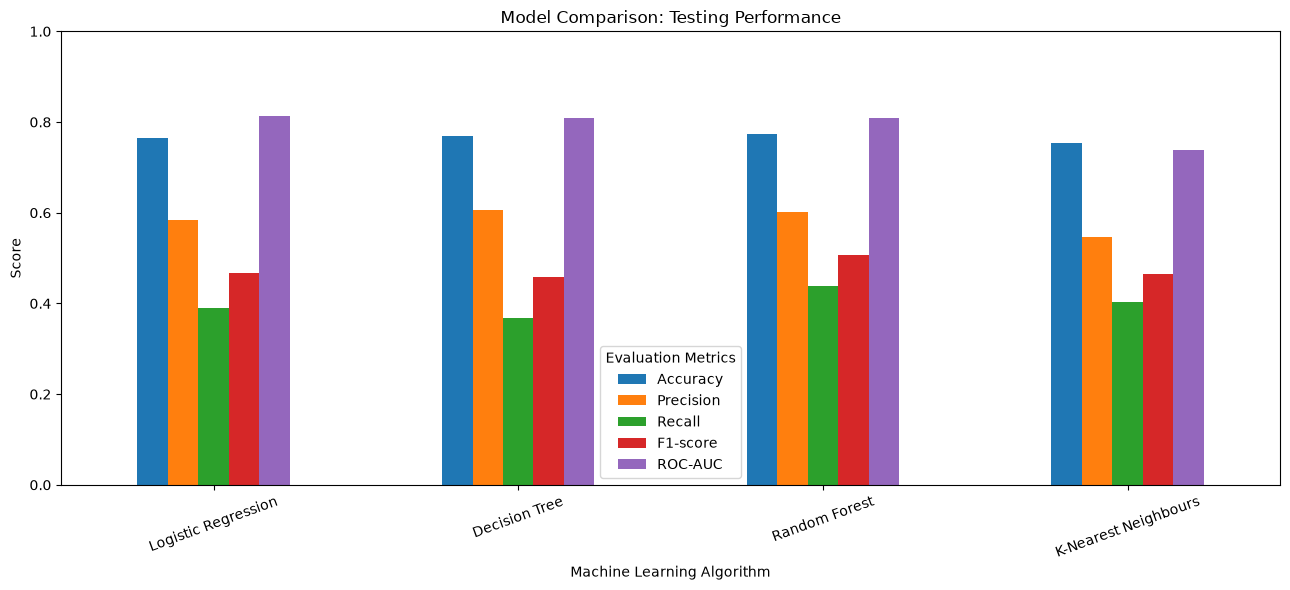

In [79]:
#Plot a comparison of the test metrics
# Keep only testing results
test_results = performance_table[
    performance_table["Dataset"] == "Test"
].set_index("Algorithm")

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

ax = test_results[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Model Comparison: Testing Performance")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()